## Libraries

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [49]:
PROJECT_PATH = Path.cwd().parents[1]

In [50]:
DATA_DIR = PROJECT_PATH / "ml" / "data" / "raw" / "ml-100k" / "ml-100k"

In [51]:
RATINGS_FILE = DATA_DIR / "u.data"
MOVIES_FILE = DATA_DIR / "u.item"

In [52]:
ratings = pd.read_csv(
    RATINGS_FILE,
    sep="\t",
    names=['user_id', 'movie_id', 'rating', 'timestamp'],
    encoding='latin-1',
)

In [53]:
movie_columns = [
    "movie_id",
    "title",
    "release_date",
    "video_release_date",
    "imdb_url",
    "unknown",
    "action",
    "adventure",
    "animation",
    "children",
    "comedy",
    "crime",
    "documentary",
    "drama",
    "fantasy",
    "film_noir",
    "horror",
    "musical",
    "mystery",
    "romance",
    "sci_fi",
    "thriller",
    "war",
    "western",
]

In [54]:
movies = pd.read_csv(
    MOVIES_FILE,
    sep="|",
    names=movie_columns,
    encoding='latin-1'
)

In [55]:
len(ratings)

100000

In [56]:
print(f"Unique users: {ratings['user_id'].nunique():,}")
print(f"Unique rated movies: {ratings['movie_id'].nunique():,}")
print(f"Movies in metadata: {movies['movie_id'].nunique():,}")


Unique users: 943
Unique rated movies: 1,682
Movies in metadata: 1,682


- There are 943 unique users.
- There are 1682 unique movies.

In [57]:
ratings.head()

,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [58]:
ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   user_id    100000 non-null  int64
 1   movie_id   100000 non-null  int64
 2   rating     100000 non-null  int64
 3   timestamp  100000 non-null  int64
dtypes: int64(4)
memory usage: 3.1 MB


The ratings dataset has 4 columns and 100000 rows

In [59]:
print("\nData types:")
print(ratings.dtypes)
print("\nMissing values:")
print(ratings.isnull().sum())
print(f"\nDuplicate rating records: {ratings.duplicated().sum():,}")


Data types:
user_id      int64
movie_id     int64
rating       int64
timestamp    int64
dtype: object

Missing values:
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

Duplicate rating records: 0


- Inside Rating dataset all data are integer type.
- No null and duplicate value found

In [60]:
print(ratings['rating'].value_counts().sort_index())
print(f'Average rating: ', ratings['rating'].mean())
print(f'Minimum rating: ', ratings['rating'].min())
print(f'Maximum rating: ', ratings['rating'].max())

rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64
Average rating:  3.52986
Minimum rating:  1
Maximum rating:  5


In [61]:
ratings.describe()

,user_id,movie_id,rating,timestamp
count,100000.00000,100000.000000,100000.000000,1.000000e+05
mean,462.48475,425.530130,3.529860,8.835289e+08
std,266.61442,330.798356,1.125674,5.343856e+06
min,1.00000,1.000000,1.000000,8.747247e+08
25%,254.00000,175.000000,3.000000,8.794487e+08
50%,447.00000,322.000000,4.000000,8.828269e+08
75%,682.00000,631.000000,4.000000,8.882600e+08
max,943.00000,1682.000000,5.000000,8.932866e+08


- The data has 100,000 ratings.
- Ratings go from 1 to 5.
- The average rating is 3.53.
- The middle rating (median) is 4.
- Half of all ratings are between 3 and 4.
- User IDs go from 1 to 943, so there are 943 users.
- Movie IDs go from 1 to 1682, which matches the 1,682 movies in the movie data.
- The `timestamp` column is a time in seconds. All ratings were made in a short period, so it is not very useful unless we change it to a date.

In [62]:
movies.head()

,movie_id,title,release_date,video_release_date,imdb_url,unknown,action,adventure,animation,children,...,fantasy,film_noir,horror,musical,mystery,romance,sci_fi,thriller,war,western
0,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,GoldenEye (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,Four Rooms (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,4,Get Shorty (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Copycat (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995),0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [63]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 1682 entries, 0 to 1681
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   movie_id            1682 non-null   int64  
 1   title               1682 non-null   str    
 2   release_date        1681 non-null   str    
 3   video_release_date  0 non-null      float64
 4   imdb_url            1679 non-null   str    
 5   unknown             1682 non-null   int64  
 6   action              1682 non-null   int64  
 7   adventure           1682 non-null   int64  
 8   animation           1682 non-null   int64  
 9   children            1682 non-null   int64  
 10  comedy              1682 non-null   int64  
 11  crime               1682 non-null   int64  
 12  documentary         1682 non-null   int64  
 13  drama               1682 non-null   int64  
 14  fantasy             1682 non-null   int64  
 15  film_noir           1682 non-null   int64  
 16  horror           

- The data has 1,682 movies and 24 columns.
- `video_release_date` is fully empty (0 non-null), so we can drop it.
- `release_date` has 1 missing value.
- `imdb_url` has 3 missing values.
- The other columns have no missing values.
- 19 columns (`unknown` to `western`) are genre columns with 0 or 1 values.
- A movie can have more than one genre.

In [64]:
movies.isna().sum()

movie_id                 0
title                    0
release_date             1
video_release_date    1682
imdb_url                 3
unknown                  0
action                   0
adventure                0
animation                0
children                 0
comedy                   0
crime                    0
documentary              0
drama                    0
fantasy                  0
film_noir                0
horror                   0
musical                  0
mystery                  0
romance                  0
sci_fi                   0
thriller                 0
war                      0
western                  0
dtype: int64

In [65]:
movies.describe()

,movie_id,video_release_date,unknown,action,adventure,animation,children,comedy,crime,documentary,...,fantasy,film_noir,horror,musical,mystery,romance,sci_fi,thriller,war,western
count,1682.000000,0.0,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,...,1682.00000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000
mean,841.500000,NaN,0.001189,0.149227,0.080262,0.024970,0.072533,0.300238,0.064804,0.029727,...,0.01308,0.014269,0.054697,0.033294,0.036266,0.146849,0.060048,0.149227,0.042212,0.016052
std,485.695893,NaN,0.034473,0.356418,0.271779,0.156081,0.259445,0.458498,0.246253,0.169882,...,0.11365,0.118632,0.227455,0.179456,0.187008,0.354061,0.237646,0.356418,0.201131,0.125714
min,1.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,421.250000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,841.500000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1261.750000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1682.000000,NaN,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [66]:
movies.loc[:, 'unknown':].sum().sort_values(ascending=False)

drama          725
comedy         505
action         251
thriller       251
romance        247
adventure      135
children       122
crime          109
sci_fi         101
horror          92
war             71
mystery         61
musical         56
documentary     50
animation       42
western         27
film_noir       24
fantasy         22
unknown          2
dtype: int64

- Drama is the biggest genre, with 725 movies. Comedy is next, with 505.
- Action and thriller are tied at 251 each. Romance is close, with 247.
- Adventure (135), children (122), crime (109) and sci-fi (101) are in the middle.
- Small genres are western (27), film noir (24) and fantasy (22).
- `unknown` has only 2 movies.
- Drama is about 43% of all movies (725 out of 1,682).
- The counts add up to more than 1,682 because a movie can have more than one genre.

In [67]:
ratings_with_movies = ratings.merge(
    movies[['movie_id', 'title']],
    on='movie_id',
    how='left',
    validate='many_to_one',
)

In [68]:
ratings_with_movies.head()

,user_id,movie_id,rating,timestamp,title
0,196,242,3,881250949,Kolya (1996)
1,186,302,3,891717742,L.A. Confidential (1997)
2,22,377,1,878887116,Heavyweights (1994)
3,244,51,2,880606923,Legends of the Fall (1994)
4,166,346,1,886397596,Jackie Brown (1997)


In [69]:
most_rated = (
    ratings_with_movies.groupby('title')
    .agg(
        rating_count = ('rating', 'size'),
        average_rating = ('rating', 'mean')
    )
    .sort_values('rating_count', ascending=False)
    .head(10)
)

In [70]:
most_rated.round(2).to_dict()

{'rating_count': {'Star Wars (1977)': 583,
  'Contact (1997)': 509,
  'Fargo (1996)': 508,
  'Return of the Jedi (1983)': 507,
  'Liar Liar (1997)': 485,
  'English Patient, The (1996)': 481,
  'Scream (1996)': 478,
  'Toy Story (1995)': 452,
  'Air Force One (1997)': 431,
  'Independence Day (ID4) (1996)': 429},
 'average_rating': {'Star Wars (1977)': 4.36,
  'Contact (1997)': 3.8,
  'Fargo (1996)': 4.16,
  'Return of the Jedi (1983)': 4.01,
  'Liar Liar (1997)': 3.16,
  'English Patient, The (1996)': 3.66,
  'Scream (1996)': 3.44,
  'Toy Story (1995)': 3.88,
  'Air Force One (1997)': 3.63,
  'Independence Day (ID4) (1996)': 3.44}}

- These are the 10 most rated movies.
- Star Wars (1977) has the most ratings (583) and a high average of 4.36.
- Fargo (1996) is also rated high, with an average of 4.16 and 508 ratings.
- Return of the Jedi (1983) has 507 ratings and an average of 4.01.
- Liar Liar (1997) has many ratings (485) but a low average of 3.16.
- Scream (1996) and Independence Day (1996) have the same average of 3.44.
- Most of these movies are from the 1990s, plus two older Star Wars films.
- Many ratings do not always mean a high rating. Popular movies can still be rated low.

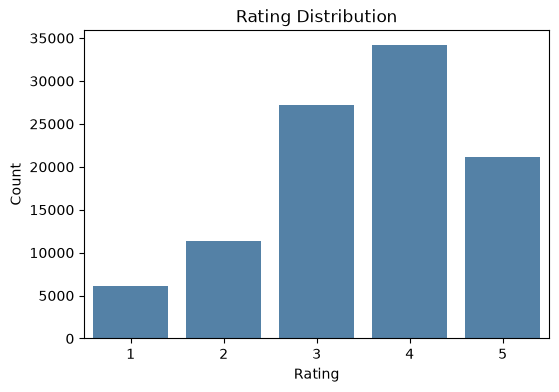

In [71]:
plt.figure(figsize=(6, 4))
sns.countplot(x='rating', data=ratings, color='steelblue')
plt.title('Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

**Plot 1: Rating Distribution**
- Rating 4 is the most common (34,174), then rating 3, then rating 5 (21,201).
- Low ratings are rare. Rating 1 is the smallest group, at about 6,000.
- Users tend to give good ratings. Ratings of 4 and 5 together are more than half of all ratings.

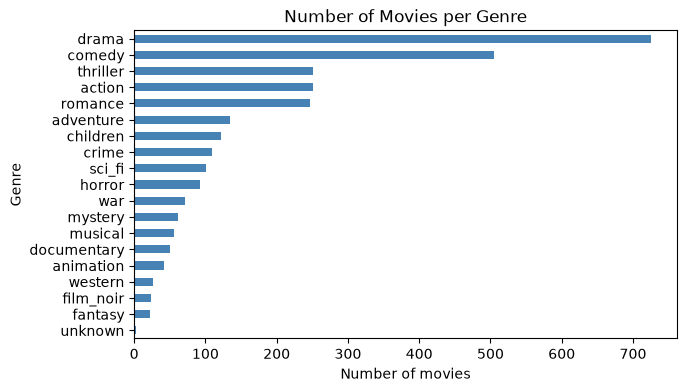

In [72]:

genre_counts = movies.loc[:, 'unknown':].sum().sort_values()
plt.figure(figsize=(7, 4))
genre_counts.plot(kind='barh', color='steelblue')
plt.title('Number of Movies per Genre')
plt.xlabel('Number of movies')
plt.ylabel('Genre')
plt.show()

**Plot 2: Number of Movies per Genre**
- Drama is the biggest genre (725 movies), then comedy (505).
- Thriller, action and romance are close to each other, at about 250 each.
- Western, film noir, fantasy and unknown have very few movies.
- There is a big gap between the top 2 genres and the rest.

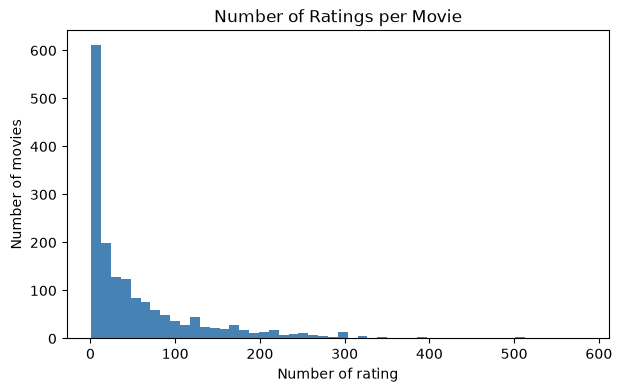

In [73]:
rating_per_movie = ratings.groupby('movie_id').size()
plt.figure(figsize=(7, 4))
plt.hist(rating_per_movie, bins=50, color='steelblue')
plt.title('Number of Ratings per Movie')
plt.xlabel('Number of rating')
plt.ylabel('Number of movies')
plt.show()

**Plot 3: Number of Ratings per Movie**
- The chart leans to the left. About 600 movies have only a few ratings.
- Only a small number of movies have more than 300 ratings. The most rated movie has 583.
- The average rating of a movie with very few ratings is not reliable.
- When we find top-rated movies, we should use a minimum rating count, like 100.

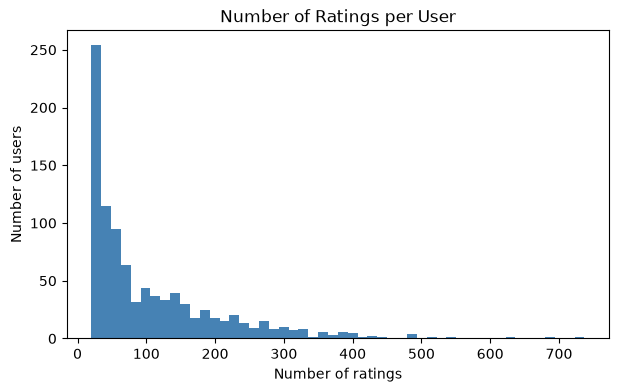

In [74]:
ratings_per_user = ratings.groupby('user_id').size()
plt.figure(figsize=(7, 4))
plt.hist(ratings_per_user, bins=50, color='steelblue')
plt.title('Number of Ratings per User')
plt.xlabel('Number of ratings')
plt.ylabel('Number of users')
plt.show()

**Plot 4: Number of Ratings per User**
- The chart leans to the left. The tallest bar is near 20 to 30 ratings, with about 250 users.
- Most users rated fewer than 100 movies.
- A few users rated a lot, up to about 730 movies.
- No user has fewer than 20 ratings.

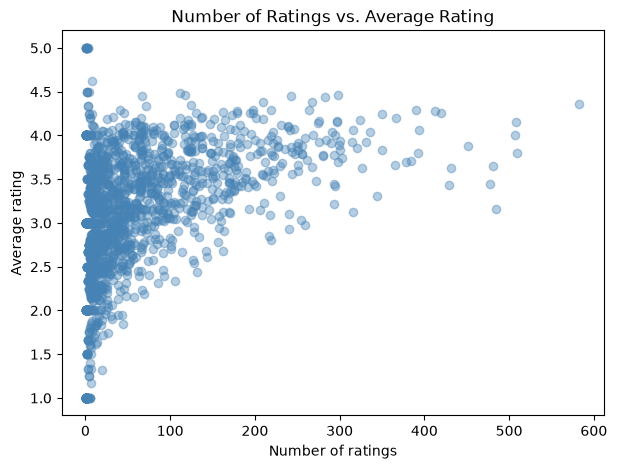

In [75]:
movie_stats = ratings.groupby('movie_id').agg(
    rating_count=('rating', 'size'),
    average_rating=('rating', 'mean')
)

plt.figure(figsize=(7, 5))
plt.scatter(movie_stats['rating_count'], movie_stats['average_rating'], alpha=0.4, color='steelblue')
plt.title('Number of Ratings vs. Average Rating')
plt.xlabel('Number of ratings')
plt.ylabel('Average rating')
plt.show()

**Plot 6: Number of Ratings vs. Average Rating**
- Movies with few ratings are spread wide, from 1.0 to 5.0.
- All the movies with a perfect 5.0 average have very few ratings, so that score is not reliable.
- As the number of ratings grows, the dots come closer together. Movies with more than 200 ratings are mostly between 3.0 and 4.5.
- Movies with many ratings rarely have a low average. Very few are below 3.0.
- Movies with many ratings tend to have higher averages. Popular movies are often liked more.
- Star Wars (about 583 ratings, average 4.36) is the far right dot.

In [77]:
title_stats = ratings_with_movies.groupby('title').agg(
    rating_count=('rating', 'size'),
    average_rating=('rating', 'mean')
)

top_rated = (
    title_stats[title_stats['rating_count'] >= 100]
    .sort_values('average_rating', ascending=False)
    .head(10)
)

top_rated.round(2)

,rating_count,average_rating
title,,
"Close Shave, A (1995)",112,4.49
Schindler's List (1993),298,4.47
"Wrong Trousers, The (1993)",118,4.47
Casablanca (1942),243,4.46
"Shawshank Redemption, The (1994)",283,4.45
Rear Window (1954),209,4.39
"Usual Suspects, The (1995)",267,4.39
Star Wars (1977),583,4.36
12 Angry Men (1957),125,4.34


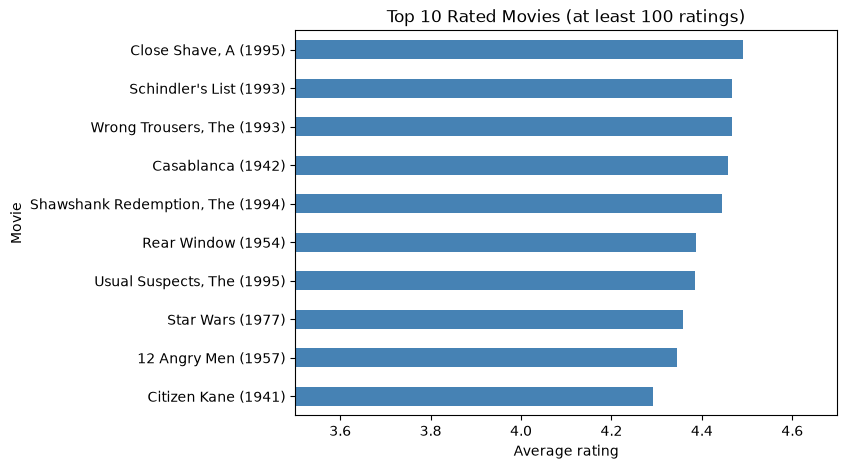

In [78]:
top_rated['average_rating'].sort_values().plot(kind='barh', color='steelblue', figsize=(7, 5))
plt.title('Top 10 Rated Movies (at least 100 ratings)')
plt.xlabel('Average rating')
plt.ylabel('Movie')
plt.xlim(3.5, 4.7)
plt.show()

**Top 10 Rated Movies (at least 100 ratings)**
- A Close Shave (1995) is first, with an average of about 4.49.
- Schindler's List (1993) and The Wrong Trousers (1993) are next, both at about 4.47.
- Casablanca (1942) and The Shawshank Redemption (1994) are also near the top, at about 4.45.
- Star Wars (1977) is in the top 10 and is also the most rated movie.
- Half of the movies are old classics: Casablanca, Rear Window, Star Wars, 12 Angry Men and Citizen Kane.
- The averages are close to each other, from about 4.29 to 4.49.
- Only movies with at least 100 ratings are included, so these averages are more

## Summary of Findings

- The data has 100,000 ratings from 943 users on 1,682 movies.
- The average rating is 3.53. Rating 4 is the most common, and most ratings are 3 or higher.
- Drama (725 movies) and comedy (505 movies) are the biggest genres.
- Many movies have very few ratings, and a few movies have a lot. Star Wars (1977) has the most, with 583.
- Most users rated fewer than 100 movies. Every user rated at least 20.
- Movies with few ratings have unreliable averages. Some have a perfect 5.0 with only 1 or 2 ratings.
- Movies with many ratings tend to have higher averages.
- Among movies with at least 100 ratings, A Close Shave (1995) has the highest average, at about 4.49. Many of the top movies are old classics.